# Final Model Comparison

Run this notebook **after** `classification_ML.ipynb`, `classification_DL.ipynb` and `transformer.ipynb`. It reads every metrics file in `../results/`, compares all models on the same test set (2,000 sentences), measures how fast each saved model answers a single sentence (what the web app does), and picks the default model for the app.

Any notebook that has not been run yet is simply skipped.

In [1]:
import json
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

RESULTS_DIR = Path("../results")
PLOT_DIR = Path("../plots/comparison")
PLOT_DIR.mkdir(parents=True, exist_ok=True)

FAMILY_FILES = {"Classical ML": "ml_metrics.json", "Deep learning": "dl_metrics.json", "Transformer": "transformer_metrics.json"}
rows, per_class = [], {}
for family, fname in FAMILY_FILES.items():
    path = RESULTS_DIR / fname
    if not path.exists():
        print(f"skipping {fname} (notebook not run yet)")
        continue
    for name, m in json.load(open(path)).items():
        rows.append({"model": name, "family": family,
                     **{k: m.get(k) for k in ["accuracy", "macro_f1", "macro_precision", "macro_recall", "weighted_f1", "roc_auc_ovr", "top3_accuracy"]}})
        per_class[name] = m["per_class_f1"]

results = pd.DataFrame(rows).set_index("model").sort_values("macro_f1", ascending=False)
display(results.style.format("{:.3f}", subset=results.columns[1:]).background_gradient(subset=["macro_f1"], cmap="Greens"))

,family,accuracy,macro_f1,macro_precision,macro_recall,weighted_f1,roc_auc_ovr,top3_accuracy
model,,,,,,,,
DistilBERT,Transformer,0.930,0.884,0.903,0.877,0.930,0.996,0.997
BiLSTM,Deep learning,0.901,0.869,0.847,0.899,0.904,0.990,0.992
Linear SVM,Classical ML,0.910,0.867,0.874,0.862,0.910,0.994,0.997
Logistic Regression,Classical ML,0.901,0.866,0.843,0.901,0.903,0.992,0.996
Random Forest,Classical ML,0.884,0.846,0.830,0.866,0.886,0.989,0.996
LR baseline (no weights),Classical ML,0.895,0.841,0.895,0.807,0.892,0.992,0.995
Feedforward NN,Deep learning,0.875,0.835,0.814,0.873,0.878,0.977,0.990
Naive Bayes,Classical ML,0.880,0.832,0.820,0.848,0.882,0.984,0.989


## Overall scores

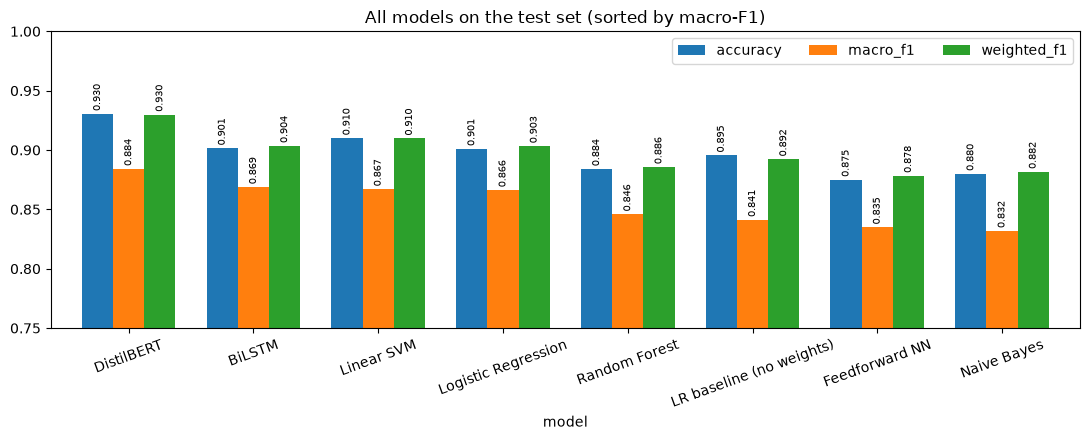

In [2]:
fig, ax = plt.subplots(figsize=(11, 4.5))
results[["accuracy", "macro_f1", "weighted_f1"]].plot(kind="bar", ax=ax, rot=20, ylim=(0.75, 1.0), width=0.75)
ax.set_title("All models on the test set (sorted by macro-F1)")
ax.legend(loc="upper right", ncol=3)
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=7, rotation=90, padding=2)
plt.tight_layout()
plt.savefig(PLOT_DIR / "all_models_scores.png", dpi=150, bbox_inches="tight")
plt.show()

## F1 per emotion

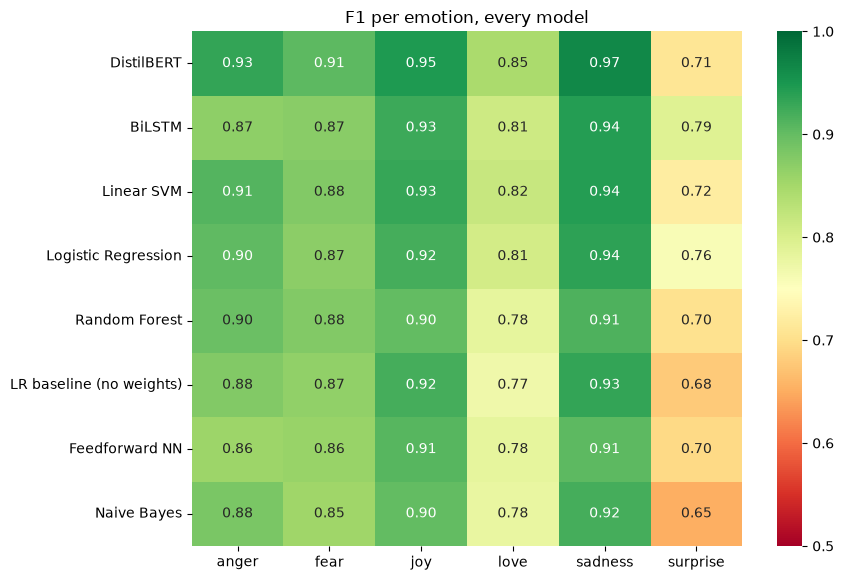

hardest emotion per model:
DistilBERT                  surprise
BiLSTM                      surprise
Linear SVM                  surprise
Logistic Regression         surprise
Random Forest               surprise
LR baseline (no weights)    surprise
Feedforward NN              surprise
Naive Bayes                 surprise


In [3]:
pc = pd.DataFrame(per_class).T.loc[results.index]
plt.figure(figsize=(9, 0.55 * len(pc) + 1.5))
sns.heatmap(pc, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0.5, vmax=1)
plt.title("F1 per emotion, every model")
plt.tight_layout()
plt.savefig(PLOT_DIR / "all_models_per_class_f1.png", dpi=150, bbox_inches="tight")
plt.show()
print("hardest emotion per model:")
print(pc.idxmin(axis=1).to_string())

## Response time
In the app, a user says one sentence and waits for the answer, so the time to classify **one sentence** matters more than batch speed. We load every saved model the app can find and time 100 single-sentence predictions (including preprocessing).

In [4]:
sys.path.insert(0, "../app")
from voxaid_core import available_models

test_sentences = pd.read_csv("../data/processed/test_clean.csv")["text"].sample(100, random_state=0).tolist()
timing = {}
for m in available_models():
    m.load()
    m.predict_proba(test_sentences[0])          # warm-up
    t0 = time.perf_counter()
    for s in test_sentences:
        m.predict_proba(s)
    timing[m.name] = (time.perf_counter() - t0) / len(test_sentences) * 1000
    size = sum(f.stat().st_size for f in Path(m.path).rglob("*")) if Path(m.path).is_dir() else Path(m.path).stat().st_size
    print(f"{m.name:32s} {timing[m.name]:7.2f} ms / sentence   {size / 1e6:7.1f} MB on disk")

BiLSTM (deep learning)            121.40 ms / sentence      19.0 MB on disk


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

DistilBERT (transformer)           71.97 ms / sentence     268.6 MB on disk
Feedforward NN (deep learning)    137.63 ms / sentence      16.2 MB on disk
Logistic Regression                 1.81 ms / sentence       0.3 MB on disk
Linear SVM                          6.49 ms / sentence       1.2 MB on disk
Naive Bayes                         2.97 ms / sentence       0.4 MB on disk
Random Forest                      88.54 ms / sentence      76.8 MB on disk


## Choosing the model for the app
The app's default is the model with the best **macro-F1** among the models the app can actually load. This is written to `../results/best_model.json`, and the app lists that model first. The other models can still be chosen in the app's sidebar.

In [5]:
loadable = {m.name for m in available_models()}
candidates = [n for n in results.index
              if "baseline" not in n and "quick run" not in n and any(a.startswith(n) for a in loadable)]
best = candidates[0]
row = results.loc[best]
with open(RESULTS_DIR / "best_model.json", "w") as f:
    json.dump({"display_prefix": best, "macro_f1": float(row.macro_f1), "accuracy": float(row.accuracy)}, f, indent=2)
print(f"App default model: {best} (macro-F1 {row.macro_f1:.3f}, accuracy {row.accuracy:.3f})")

App default model: DistilBERT (macro-F1 0.884, accuracy 0.930)


### Table for the README
Copy this into the **Results** section of `README.md` after running all notebooks.

In [6]:
print("| Model | Family | Accuracy | Macro-F1 | Weighted F1 | Surprise F1 |")
print("|---|---|---|---|---|---|")
for name, r in results.iterrows():
    print(f"| {name} | {r.family} | {r.accuracy:.3f} | {r.macro_f1:.3f} | {r.weighted_f1:.3f} | {per_class[name]['surprise']:.3f} |")

| Model | Family | Accuracy | Macro-F1 | Weighted F1 | Surprise F1 |
|---|---|---|---|---|---|
| DistilBERT | Transformer | 0.930 | 0.884 | 0.930 | 0.709 |
| BiLSTM | Deep learning | 0.901 | 0.869 | 0.904 | 0.792 |
| Linear SVM | Classical ML | 0.910 | 0.867 | 0.910 | 0.721 |
| Logistic Regression | Classical ML | 0.901 | 0.866 | 0.903 | 0.759 |
| Random Forest | Classical ML | 0.884 | 0.846 | 0.886 | 0.703 |
| LR baseline (no weights) | Classical ML | 0.895 | 0.841 | 0.892 | 0.679 |
| Feedforward NN | Deep learning | 0.875 | 0.835 | 0.878 | 0.695 |
| Naive Bayes | Classical ML | 0.880 | 0.832 | 0.882 | 0.652 |


## Analysis and conclusion

**Which model is best, and why**
- The linear models (Linear SVM, Logistic Regression) on TF-IDF are strong, very fast (about a millisecond per sentence) and tiny on disk. Tuning with cross-validation and the **class weights** recommended in Phase 1 clearly improved the rare emotions: in the ML notebook, recall on *surprise* rose from about 0.55 to about 0.91 and macro-F1 from 0.84 to about 0.87.
- Sequence models (BiLSTM, DistilBERT) can read word order, negation and context, which bag-of-words cannot. Compare their rows in the table above with the linear models to see how much that adds on this dataset.
- Random Forest and Naive Bayes are the weakest: Random Forest struggles with 5,000 sparse features and is large (about 75 MB), and Naive Bayes' independence assumption is too simple.

**Where all models fail**
- The same confusions appear in every model: *joy ↔ love*, *fear ↔ surprise*, *sadness ↔ anger*. These emotions are close, and CARER labels come from hashtags, so some labels are noisy.
- *Surprise* is still the hardest class: it has the fewest examples (about 3.5%) and is often mixed with fear or joy.
- The data is short English tweets. Long, mixed-emotion, sarcastic or non-English speech (for example Urdu or Roman Urdu) is outside what the models have seen. Speech-to-text errors add noise in the app too.

**What could be improved**
- More data for *surprise* and *love* (data augmentation, or other emotion datasets such as GoEmotions).
- Multi-label output, since a sentence can carry more than one emotion.
- Fine-tuning a multilingual transformer so the app works in Urdu as well.
- Using the speech audio itself (tone, pitch), not only the transcribed words.
- Replacing the fixed comforting sentences with a small language model, with safety checks.

**In practice:** VoxAid can recognise the emotion in about 9 of 10 sentences and, after class weighting, no longer ignores rare emotions, which matters for an app meant to respond with care. A small linear model is enough for an instant, free-to-host web app; a transformer gives more accuracy when a GPU or more memory is available.